In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make our results reproducible
np.random.seed(42)

print("ColdGuard AI - Environment ready!")


ColdGuard AI - Environment ready!


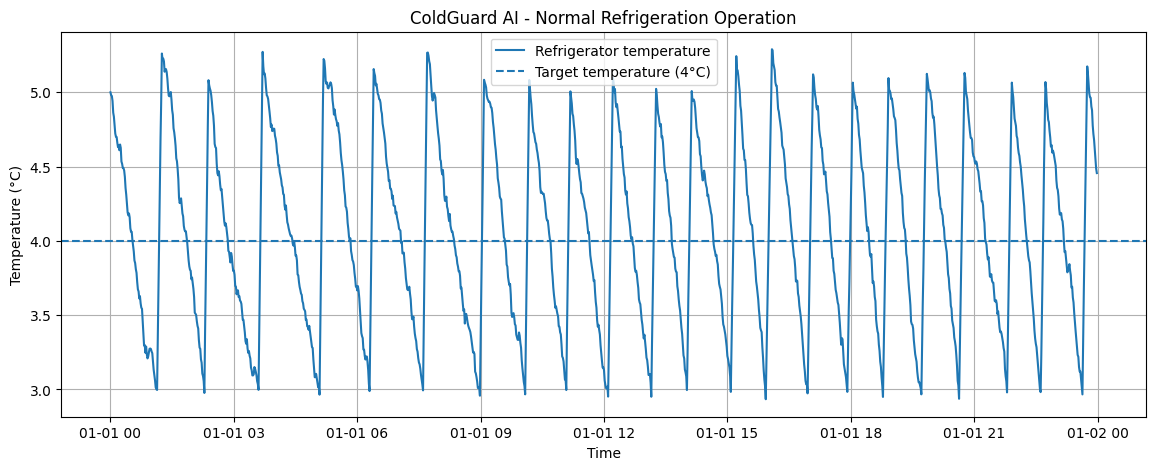

Dataset saved successfully!
Number of sensor readings: 1440
Average refrigerator temperature: 4.06 °C
Maximum refrigerator temperature: 5.29 °C


In [3]:

# Simulation settings
duration_hours = 24
interval_minutes = 1

total_samples = duration_hours * 60

time = np.arange(total_samples)

# Ambient temperature varies during the day
ambient_temp = (
    25
    + 4 * np.sin(2 * np.pi * time / 1440)
    + np.random.normal(0, 0.3, total_samples)
)

# Refrigerator settings
target_temp = 4.0
fridge_temp = np.zeros(total_samples)
compressor_on = np.zeros(total_samples)

# Initial refrigerator temperature
fridge_temp[0] = 5.0

# Simulate the cooling process
for i in range(1, total_samples):

    # Compressor control
    if fridge_temp[i-1] >= 5.0:
        compressor_on[i] = 1
    elif fridge_temp[i-1] <= 3.0:
        compressor_on[i] = 0
    else:
        compressor_on[i] = compressor_on[i-1]

    # Temperature changes
    if compressor_on[i] == 1:
        cooling_rate = 0.08
        warming_rate = 0.002
    else:
        cooling_rate = 0
        warming_rate = 0.015

    fridge_temp[i] = (
        fridge_temp[i-1]
        + warming_rate * (ambient_temp[i] - fridge_temp[i-1])
        - cooling_rate
        + np.random.normal(0, 0.03)
    )

# Create a timestamp
timestamps = pd.date_range(
    start="2026-01-01",
    periods=total_samples,
    freq="min"
)

# Store everything in a DataFrame
df = pd.DataFrame({
    "timestamp": timestamps,
    "ambient_temp": ambient_temp,
    "fridge_temp": fridge_temp,
    "compressor_on": compressor_on
})

df.head()



plt.figure(figsize=(14, 5))

plt.plot(
    df["timestamp"],
    df["fridge_temp"],
    label="Refrigerator temperature"
)

plt.axhline(
    y=4,
    linestyle="--",
    label="Target temperature (4°C)"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("ColdGuard AI - Normal Refrigeration Operation")
plt.legend()
plt.grid(True)

plt.show()


df.to_csv("coldguard_normal_data.csv", index=False)

print("Dataset saved successfully!")
print("Number of sensor readings:", len(df))
print("Average refrigerator temperature:",
      round(df["fridge_temp"].mean(), 2), "°C")
print("Maximum refrigerator temperature:",
      round(df["fridge_temp"].max(), 2), "°C")



In [4]:

# Make a copy of our normal dataset
df_fault = df.copy()

# Fault starts after 12 hours
fault_start = 12 * 60

# Simulate compressor failure
df_fault.loc[fault_start:, "compressor_on"] = 0

# Simulate temperature rising after the failure
for i in range(fault_start, len(df_fault)):

    if i == fault_start:
        continue

    df_fault.loc[i, "fridge_temp"] = (
        df_fault.loc[i-1, "fridge_temp"]
        + 0.04
        + np.random.normal(0, 0.03)
    )

# Mark normal and faulty conditions
df_fault["condition"] = "Normal"

df_fault.loc[
    fault_start:, "condition"
] = "Compressor Failure"

print("Fault simulation completed!")


Fault simulation completed!


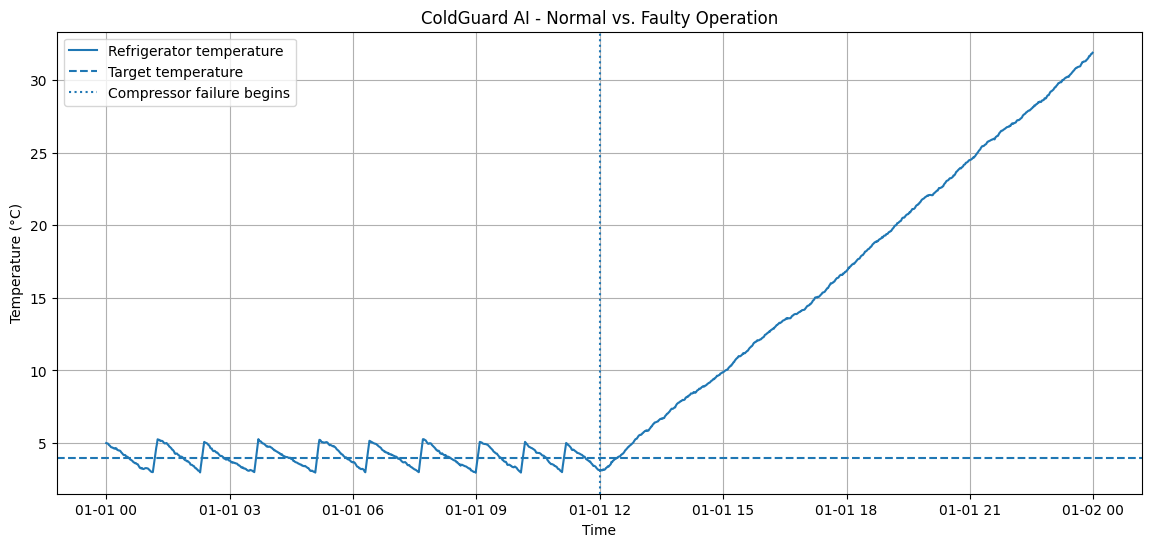

In [5]:

plt.figure(figsize=(14, 6))

plt.plot(
    df_fault["timestamp"],
    df_fault["fridge_temp"],
    label="Refrigerator temperature"
)

plt.axhline(
    y=4,
    linestyle="--",
    label="Target temperature"
)

plt.axvline(
    df_fault["timestamp"].iloc[fault_start],
    linestyle=":",
    label="Compressor failure begins"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("ColdGuard AI - Normal vs. Faulty Operation")

plt.legend()
plt.grid(True)
plt.show()


In [6]:

# Calculate temperature change over the previous 5 minutes
df_fault["temp_rate_5min"] = (
    df_fault["fridge_temp"].diff(5) / 5
)

# Define alarm parameters
TEMP_THRESHOLD = 5.0
RATE_THRESHOLD = 0.02
PERSISTENCE_MINUTES = 10

print("Alarm parameters configured.")


Alarm parameters configured.


In [7]:

# Condition 1: Temperature exceeds 5°C
df_fault["high_temperature"] = (
    df_fault["fridge_temp"] > TEMP_THRESHOLD
)

# Condition 2: Temperature is rising sufficiently quickly
df_fault["rapid_rise"] = (
    df_fault["temp_rate_5min"] > RATE_THRESHOLD
)

# Both conditions must be true
df_fault["abnormal_condition"] = (
    df_fault["high_temperature"]
    & df_fault["rapid_rise"]
)

# Require 10 consecutive abnormal readings
df_fault["alarm"] = (
    df_fault["abnormal_condition"]
    .rolling(
        window=PERSISTENCE_MINUTES,
        min_periods=PERSISTENCE_MINUTES
    )
    .sum()
    >= PERSISTENCE_MINUTES
)

print("Detection algorithm implemented!")


Detection algorithm implemented!


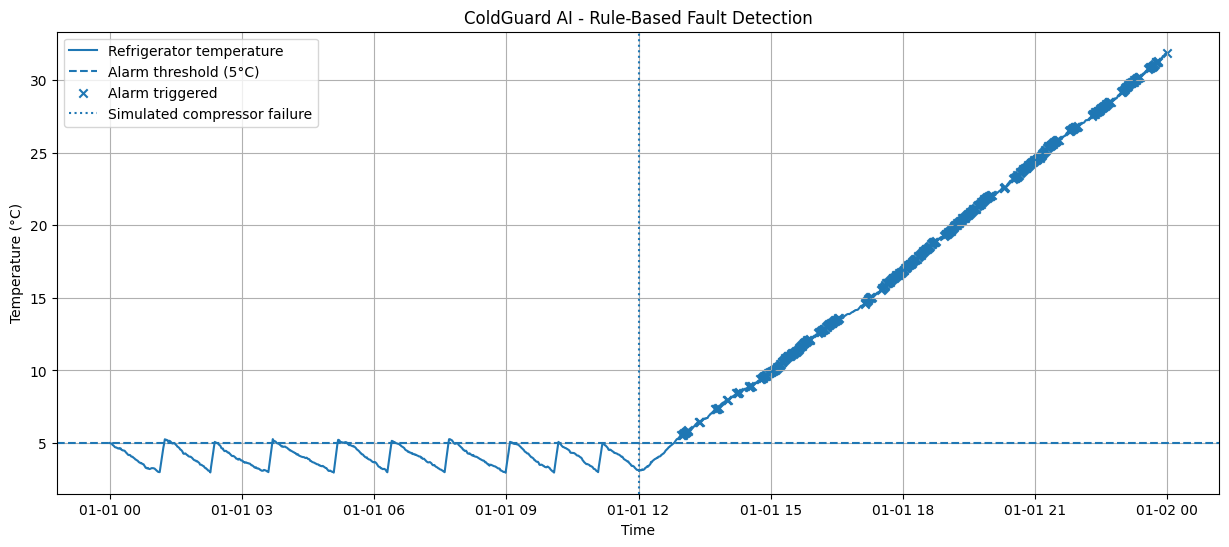

In [8]:

plt.figure(figsize=(15, 6))

plt.plot(
    df_fault["timestamp"],
    df_fault["fridge_temp"],
    label="Refrigerator temperature"
)

plt.axhline(
    y=TEMP_THRESHOLD,
    linestyle="--",
    label="Alarm threshold (5°C)"
)

# Highlight alarm periods
alarm_data = df_fault[df_fault["alarm"]]

plt.scatter(
    alarm_data["timestamp"],
    alarm_data["fridge_temp"],
    label="Alarm triggered",
    marker="x"
)

plt.axvline(
    df_fault["timestamp"].iloc[fault_start],
    linestyle=":",
    label="Simulated compressor failure"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("ColdGuard AI - Rule-Based Fault Detection")
plt.legend()
plt.grid(True)
plt.show()


In [9]:

alarm_indices = df_fault.index[df_fault["alarm"]]

if len(alarm_indices) > 0:

    first_alarm = alarm_indices[0]

    detection_time = df_fault.loc[
        first_alarm, "timestamp"
    ]

    failure_time = df_fault.loc[
        fault_start, "timestamp"
    ]

    detection_delay = (
        detection_time - failure_time
    ).total_seconds() / 60

    print("Failure started:", failure_time)
    print("First alarm:", detection_time)
    print("Detection delay:", detection_delay, "minutes")

else:
    print("No alarm detected!")


Failure started: 2026-01-01 12:00:00
First alarm: 2026-01-01 12:58:00
Detection delay: 58.0 minutes


In [10]:

df_normal_test = df.copy()

df_normal_test["temp_rate_5min"] = (
    df_normal_test["fridge_temp"].diff(5) / 5
)

df_normal_test["abnormal_condition"] = (
    (df_normal_test["fridge_temp"] > TEMP_THRESHOLD)
    &
    (df_normal_test["temp_rate_5min"] > RATE_THRESHOLD)
)

df_normal_test["alarm"] = (
    df_normal_test["abnormal_condition"]
    .rolling(window=10, min_periods=10)
    .sum()
    >= 10
)

false_alarms = df_normal_test["alarm"].sum()

print("False alarm readings:", false_alarms)
print("Total readings:", len(df_normal_test))


False alarm readings: 0
Total readings: 1440
